<a href="https://colab.research.google.com/github/tasm3/cs460-data-scienc/blob/hw5/Google_Trends.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Understanding Search Interest with Google Trends


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Load Google Trends dataset
trends = pd.read_csv('ai_tools_comparison.csv')

# Inspect the first five rows
trends.head()

,week,chatgpt,gemini,microsoft_copilot
0,2023-08-27,56,3,1
1,2023-09-03,56,3,1
2,2023-09-10,63,3,1
3,2023-09-17,64,3,1
4,2023-09-24,66,3,1


In [6]:
# Start coding here
# Use as many cells as you need
trends.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   week               54 non-null     object
 1   chatgpt            54 non-null     int64 
 2   gemini             54 non-null     int64 
 3   microsoft_copilot  54 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 1.8+ KB


In [7]:
trends['week'] = pd.to_datetime(trends['week'])
trends.dtypes

,0
week,datetime64[ns]
chatgpt,int64
gemini,int64
microsoft_copilot,int64


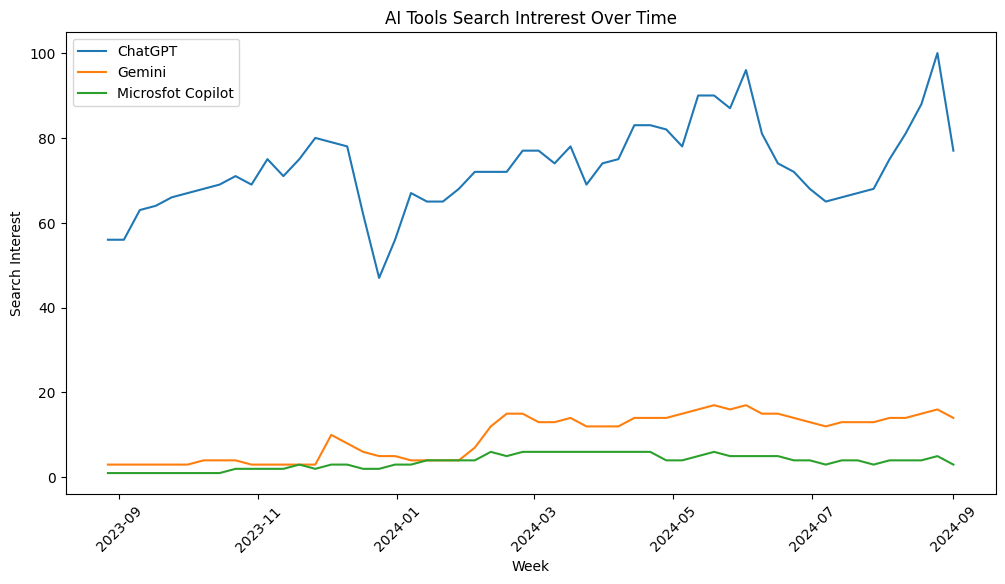

In [8]:
plt.figure(figsize=(12, 6))

plt.plot(trends['week'], trends['chatgpt'], label='ChatGPT')
plt.plot(trends['week'], trends['gemini'], label='Gemini')
plt.plot(trends['week'], trends['microsoft_copilot'], label='Microsfot Copilot')

plt.title('AI Tools Search Intrerest Over Time')
plt.xlabel('Week')
plt.ylabel('Search Interest')
plt.legend()
plt.xticks(rotation=45)
plt.show()

In [16]:
tools = ['chatgpt', 'gemini', 'microsoft_copilot']

weekly_trends = trends.set_index('week')
weekly_chng = weekly_trends[tools].pct_change()
weekly_std = weekly_chng.std()

most_consistent_tool = weekly_std.idxmin()

print(weekly_std)
print(most_consistent_tool)

chatgpt              0.090510
gemini               0.363603
microsoft_copilot    0.245632
dtype: float64
chatgpt


In [17]:
low_week = trends['chatgpt'].idxmin()
gpt_dip = trends.loc[low_week, 'week'].strftime('%B %Y')
print(gpt_dip)

December 2023


In [18]:
trends['month'] = trends['week'].dt.month_name()
monthly_avg = trends.groupby('month')[['chatgpt', 'gemini', 'microsoft_copilot']].mean()
monthly_avg

,chatgpt,gemini,microsoft_copilot
month,,,
April,80.75,13.50,5.50
August,80.00,12.40,3.60
December,64.40,6.80,2.60
February,73.25,12.25,5.25
January,66.25,4.00,3.75
July,66.50,12.75,3.50
June,78.20,14.80,4.60
March,74.40,12.80,6.00
May,86.25,16.00,5.00


In [19]:
monthly_avg['overall_avg'] = monthly_avg.mean(axis=1)
best_month = monthly_avg['overall_avg'].idxmax()
print(best_month)

May


In [20]:
print("Most consistent tool: ", most_consistent_tool)
print(type(most_consistent_tool))

print("ChatGPT's largest decline: ", gpt_dip)
print(type(gpt_dip))

print("Month with highest interest: ", best_month)
print(type(best_month))

Most consistent tool:  chatgpt
<class 'str'>
ChatGPT's largest decline:  December 2023
<class 'str'>
Month with highest interest:  May
<class 'str'>


**Conclusion**
ChatGPT had both the highest overall search interest and the most consistent weekly percentage changes, with the lowest standard deviation of 0.0905. Its lowest search interest was in December 2023. I also compared the average search interest across different months and found that May had the highest overall average.